# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The SpaceNet 8 dataset can be used for change detection and semantic segmentation. This notebooks showcases semantic segmentation on the post-event images.

## Import the required packages

In [ ]:
from aitlas.datasets import SpaceNet8Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/SpaceNet8/train/",
    "mode": "pairs"
}
dataset = SpaceNet8Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 801


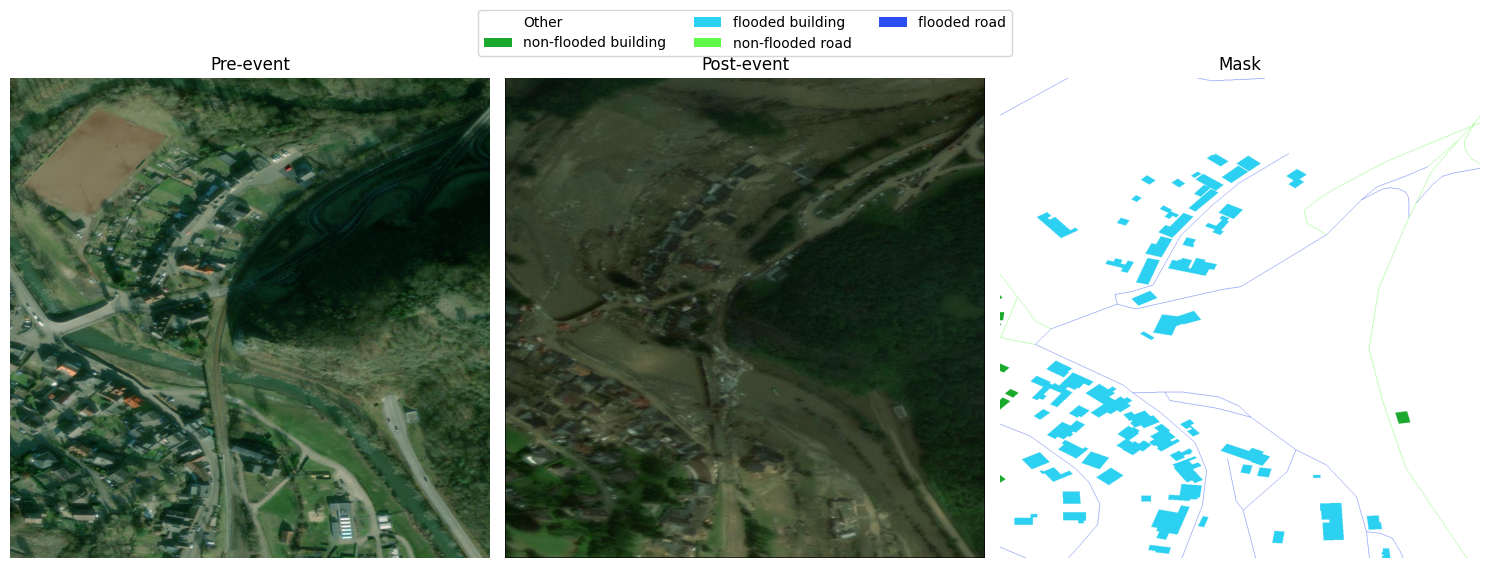

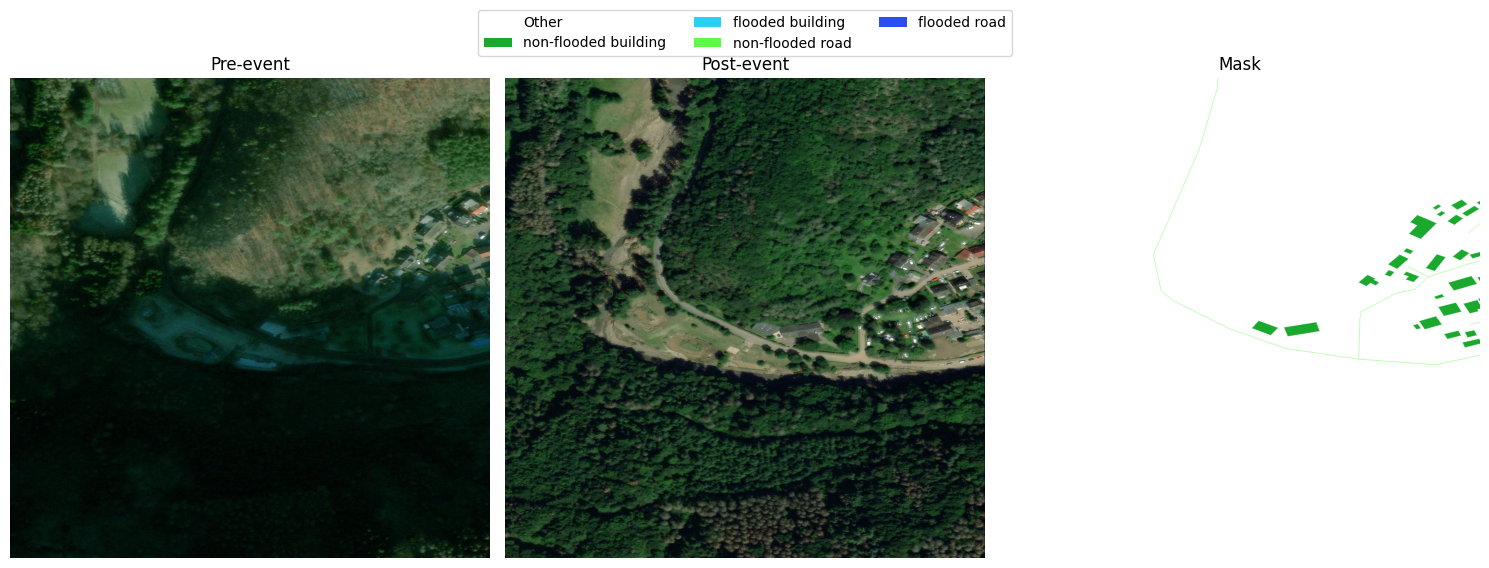

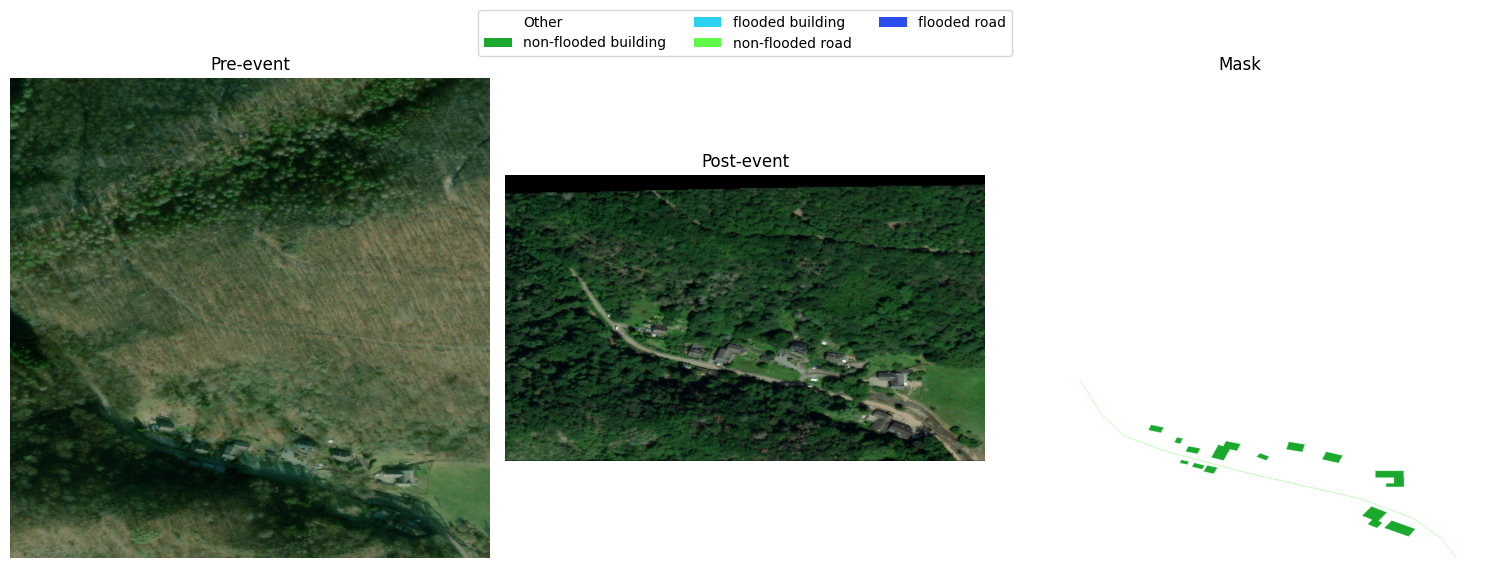

In [61]:
dataset.show_image(15);
dataset.show_image(100);
dataset.show_image(200);

In [50]:
dataset.data_distribution_table()

,Number of pixels
non-flooded building,21718462
flooded building,4028179
non-flooded road,6584188
flooded road,1419150


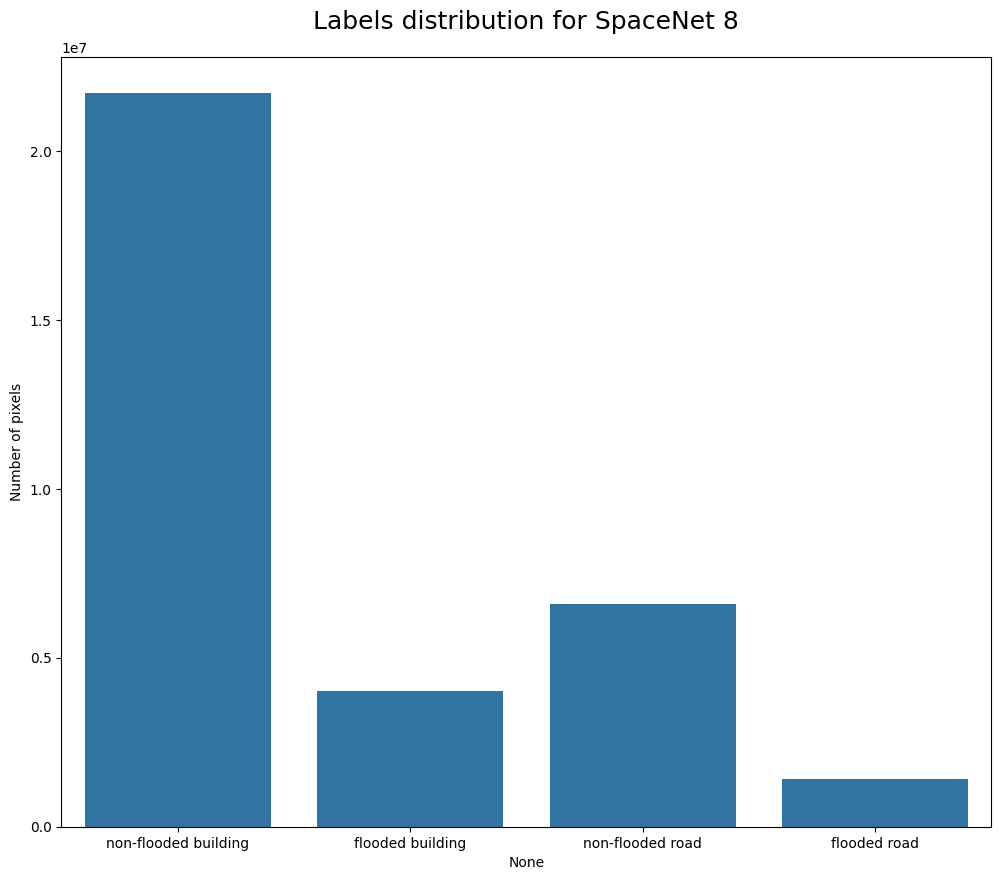

In [51]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 9,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/SpaceNet8/train/",
    "mode": "post-event",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet8Dataset(train_dataset_config)

len(train_dataset)

801

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/SpaceNet8"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [14]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-25 07:04:08,287 INFO Starting training.
training: 100%|██████████| 89/89 [00:32<00:00,  2.74it/s]
2025-09-25 07:04:40,829 INFO epoch: 1, time: 32, loss:  0.61169
testing on train set: 100%|██████████| 89/89 [00:33<00:00,  2.67it/s]
2025-09-25 07:05:16,359 INFO IOU:0.6840291771249118, IOU mean:0.19031468050961936, IOU per Class:[0.92053351 0.02757207 0.00346782 0.         0.        ]
training: 100%|██████████| 89/89 [00:33<00:00,  2.65it/s]
2025-09-25 07:05:49,941 INFO epoch: 2, time: 33, loss:  0.45964
testing on train set: 100%|██████████| 89/89 [00:32<00:00,  2.70it/s]
2025-09-25 07:06:22,934 INFO IOU:0.9212868576454564, IOU mean:0.1862662554254856, IOU per Class:[0.93133128 0.         0.         0.         0.        ]
training: 100%|██████████| 89/89 [00:34<00:00,  2.57it/s]
2025-09-25 07:06:57,612 INFO epoch: 3, time: 35, loss:  0.30694
testing on train set: 100%|██████████| 89/89 [00:32<00:00,  2.71it/s]
2025-09-25 07:07:30,525 INFO IOU:0.9418331605423634, IOU mean:0.19039

0.037766240955738536

## Predictions

2025-09-25 07:17:34,317 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet8/checkpoint.pth.tar
2025-09-25 07:17:34,649 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet8/checkpoint.pth.tar at epoch 11


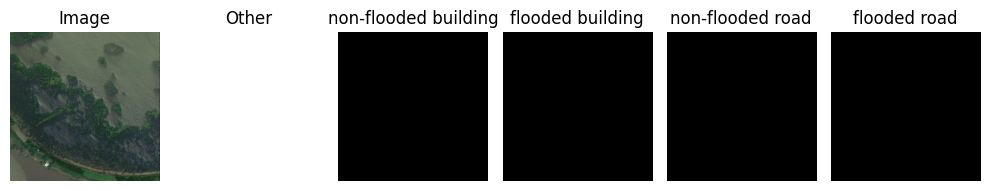

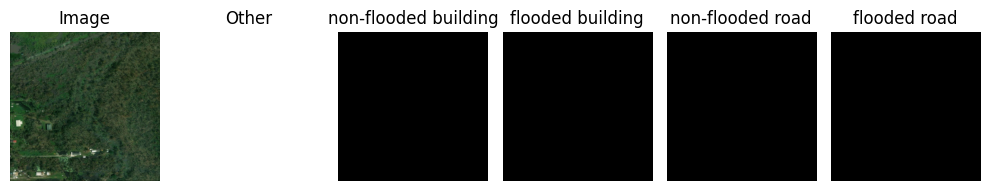

In [ ]:
model_path = "./data/experiments/SpaceNet8/checkpoint.pth.tar"
labels = ["Other",
        "non-flooded building",
        "flooded building",
        "non-flooded road",
        "flooded road"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/SpaceNet8/Louisiana-West_Test_Public/POST-event/10300100C4171800_0_0_20.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SpaceNet8/Louisiana-West_Test_Public/POST-event/10300100C4171800_0_9_28.tif')
fig = model.predict_masks(image, labels, transform)